# FGM Prevalence and Regional Attitude Comparison, Kenya — v2

This notebook is self-contained: it fits the same survey-weighted BYM2 attitude model using the selected attitude covariates, creates the regional attitude map, regenerates the two adjusted prevalence maps separately, and then produces separate and combined overlays. It does not require a previously generated attitude CSV.

The Kenya data supplied to this project contain 47 admin-1 county boundaries but no DHS cluster coordinates. The attitude model therefore uses the verified county polygon adjacency, normalized DHS weights, age as a flexible RW2 effect, selected fixed covariates, and a BYM2 county effect. Centroid points in overlays are county map symbols, not survey locations.

## 0. Configuration

In [1]:
country_name <- "Kenya"
country_iso3 <- "KEN"
survey_year <- 2022
project_root <- if (dir.exists("../02_Data")) ".." else "."
combined_dir <- file.path(project_root,"02_Data","processed",country_iso3,"combined")
prevalence_data_dir <- file.path(project_root,"02_Data","processed",country_iso3,"prevalence")
prevalence_output_dir <- file.path(project_root,"03_Outputs",country_iso3,"FGM_Prevalence")
output_dir <- file.path(project_root,"03_Outputs",country_iso3,"Prevalence_Attitude_Comparison_v2")
shapefile_path <- file.path(project_root,"02_Data","raw",as.character(survey_year),"Survey","boundaries","Kenya Boundaries","shps","sdr_subnational_boundaries.shp")
region_var_shapefile <- "DHSREGEN"
standardize_region <- function(x) {
  x |> as.character() |> toupper() |> stringr::str_replace_all("[^A-Z ]"," ") |> stringr::str_squish()
}
posterior_draws <- 300L
minimum_region_n_display <- 1L
set.seed(20260921)
dir.create(output_dir,recursive=TRUE,showWarnings=FALSE)
# end

## 1. Packages

In [2]:
required_packages <- c("tidyverse","survey","sf","spdep","INLA","ggspatial")
missing_packages <- required_packages[!vapply(required_packages,requireNamespace,logical(1),quietly=TRUE)]
if(length(missing_packages)) stop("Install missing packages: ",paste(missing_packages,collapse=", "))
suppressPackageStartupMessages({library(tidyverse);library(survey);library(sf);library(spdep)})
options(survey.lonely.psu="adjust")
theme_set(ggplot2::theme_minimal(base_size=12))
# end

## 2. Load the attitude sample, prevalence results and Kenya boundaries

In [3]:
attitude <- readRDS(file.path(combined_dir,paste0(country_iso3,"_attitude.rds")))
women_lookup <- readRDS(file.path(prevalence_data_dir,paste0(country_iso3,"_prevalence_self.rds"))) |>
  dplyr::select(resp_id,age,birth_year) |> dplyr::distinct(resp_id,.keep_all=TRUE)
attitude <- attitude |>
  dplyr::left_join(women_lookup,by=c("id"="resp_id")) |>
  dplyr::mutate(
    region=standardize_region(region)
  )
if(anyNA(attitude$age)) stop("Age join failed")

self_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_self.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Women aged 15–49")
daughter_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_daughter.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Girls aged 0–14")

boundaries <- sf::st_read(shapefile_path,quiet=TRUE) |> sf::st_make_valid() |>
  dplyr::mutate(region=standardize_region(.data[[region_var_shapefile]]))
if(length(setdiff(unique(attitude$region),boundaries$region))) stop("Unmatched attitude regions")
cat("Attitude respondents:",nrow(attitude),"\nRegions:",dplyr::n_distinct(attitude$region),"\n")
# end

Attitude respondents: 15890 
Regions: 47 


## 3. Prepare the selected covariates and regional adjacency graph

In [4]:
selected_predictors <- c("own_status","age","education","wealth","religion","ethnicity","urban_rural")
model_data <- attitude |>
  dplyr::mutate(
    own_status=factor(own_status,levels=c(0,1),labels=c("Not cut","Cut")),
    education=factor(education),wealth=factor(wealth),religion=factor(religion),
    ethnicity=factor(ethnicity),urban_rural=factor(urban_rural),age=as.numeric(age)
  ) |>
  dplyr::filter(!is.na(supports_continuation),is.finite(weight),weight>0) |>
  tidyr::drop_na(dplyr::all_of(selected_predictors)) |> droplevels()

region_sample <- model_data |>
  dplyr::group_by(region) |>
  dplyr::summarise(n_unweighted=dplyr::n(),sum_survey_weight=sum(weight),.groups="drop")
region_points <- boundaries |> sf::st_transform(3857) |> sf::st_point_on_surface() |> sf::st_transform(4326)
region_coordinates <- sf::st_coordinates(region_points)
region_lookup <- boundaries |>
  sf::st_drop_geometry() |>
  dplyr::transmute(region,region_id=dplyr::row_number(),lon=region_coordinates[,1],lat=region_coordinates[,2]) |>
  dplyr::left_join(region_sample,by="region")
model_data <- model_data |>
  dplyr::left_join(region_lookup |> dplyr::select(region,region_id),by="region") |>
  dplyr::mutate(age_id=as.integer(age-min(age)+1L),pseudo_weight=weight/mean(weight))
if(anyNA(model_data$region_id)) stop("Region join failed")
neighbors <- spdep::poly2nb(boundaries,row.names=boundaries$region)
adjacency_matrix <- spdep::nb2mat(neighbors,style="B",zero.policy=TRUE)
cat("Model rows:",nrow(model_data),"\nBYM2 regions:",nrow(region_lookup),"\nMean normalized weight:",mean(model_data$pseudo_weight),"\n")
# end

Warning message:
“st_point_on_surface assumes attributes are constant over geometries”


Model rows: 15890 
BYM2 regions: 47 
Mean normalized weight: 1 


## 4. Fit the covariate-adjusted regional BYM2 model

In [5]:
attitude_formula <- supports_continuation ~ own_status + education + wealth + religion +
  ethnicity + urban_rural +
  f(age_id,model="rw2",constr=TRUE,scale.model=TRUE) +
  f(region_id,model="bym2",graph=adjacency_matrix,scale.model=TRUE)

attitude_region_model <- INLA::inla(
  attitude_formula,family="binomial",data=model_data,weights=model_data$pseudo_weight,
  control.predictor=list(compute=TRUE,link=1),
  control.compute=list(dic=TRUE,waic=TRUE,cpo=TRUE,config=TRUE),
  control.inla=list(control.vb=list(enable=FALSE))
)
print(round(attitude_region_model$summary.fixed[,1:5,drop=FALSE],3))
cat("DIC:",attitude_region_model$dic$dic," WAIC:",attitude_region_model$waic$waic,"\n")
# end

                               mean    sd 0.025quant 0.5quant 0.975quant
(Intercept)                  -5.494 0.394     -6.267   -5.494     -4.721
own_statusCut                 1.994 0.156      1.689    1.994      2.299
educationno education         1.730 0.297      1.147    1.730      2.312
educationprimary              1.447 0.259      0.940    1.447      1.954
educationsecondary            0.939 0.259      0.431    0.939      1.446
wealthpoorer                  0.276 0.175     -0.068    0.276      0.619
wealthpoorest                 0.608 0.172      0.271    0.608      0.945
wealthricher                 -0.226 0.202     -0.622   -0.226      0.170
wealthrichest                -0.198 0.245     -0.679   -0.198      0.283
religioncatholic              0.341 0.240     -0.130    0.341      0.811
religionevangelical churches  0.358 0.231     -0.094    0.358      0.810
religionhindu                -0.327 3.168     -6.538   -0.326      5.885
religionislam                 0.650 0.337     -0.01

DIC: 3199.217  WAIC: 3245.315 


## 5. Aggregate posterior probabilities by region

In [6]:
set.seed(20260922)
samples <- INLA::inla.posterior.sample(posterior_draws,attitude_region_model,use.improved.mean=FALSE,skew.corr=FALSE)
latent_names <- rownames(samples[[1L]]$latent)
predictor_rows <- grep("^Predictor:",latent_names)
predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:","",latent_names[predictor_rows])))
if(!anyNA(predictor_numbers)) predictor_rows <- predictor_rows[order(predictor_numbers)]
if(length(predictor_rows)!=nrow(model_data)) stop("Posterior predictors do not align")
rows_by_region <- lapply(region_lookup$region_id,function(i) which(model_data$region_id==i))
region_draws <- vapply(samples,function(draw){
  probability <- stats::plogis(as.numeric(draw$latent[predictor_rows,1L]))
  vapply(rows_by_region,function(rows) stats::weighted.mean(probability[rows],model_data$weight[rows]),numeric(1L))
},numeric(nrow(region_lookup)))
if(is.null(dim(region_draws))) region_draws <- matrix(region_draws,nrow=nrow(region_lookup))
attitude_regions <- region_lookup |>
  dplyr::mutate(adjusted_support=rowMeans(region_draws),
                lower_ci=apply(region_draws,1,stats::quantile,.025,names=FALSE),
                upper_ci=apply(region_draws,1,stats::quantile,.975,names=FALSE))
readr::write_csv(attitude_regions,file.path(output_dir,paste0(country_iso3,"_adjusted_attitude_regions.csv")))
cat("Adjusted regions:",nrow(attitude_regions),"\n")
# end

Adjusted regions: 47 


## 6. Standalone regional attitude map

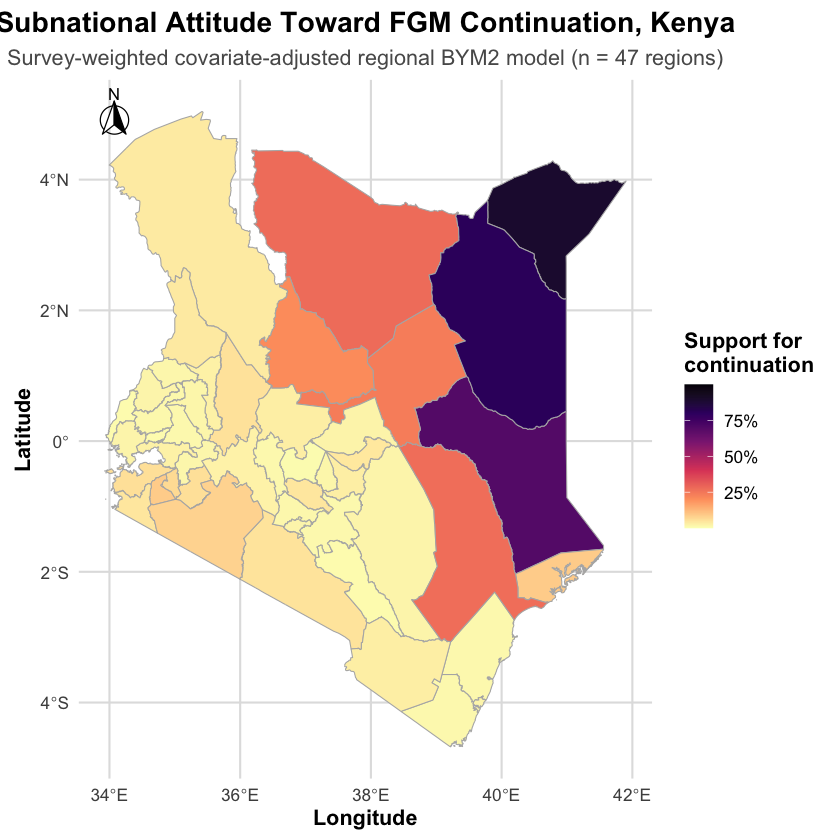

In [7]:
region_plot_data <- attitude_regions |> dplyr::filter(n_unweighted>=minimum_region_n_display)
attitude_map_data <- boundaries |> dplyr::left_join(region_plot_data,by="region")
attitude_region_map <- ggplot2::ggplot(attitude_map_data) +
  ggplot2::geom_sf(ggplot2::aes(fill=adjusted_support),color="grey70",linewidth=.30) +
  ggplot2::scale_fill_viridis_c(name="Support for\ncontinuation",option="magma",direction=-1,
    limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1)) +
  ggspatial::annotation_north_arrow(location="tl",which_north="true",
    style=ggspatial::north_arrow_fancy_orienteering,height=grid::unit(1,"cm"),width=grid::unit(1,"cm")) +
  ggplot2::coord_sf(datum=sf::st_crs(4326)) +
  ggplot2::labs(title=paste("Subnational Attitude Toward FGM Continuation,",country_name),
    subtitle=paste0("Survey-weighted covariate-adjusted regional BYM2 model (n = ",nrow(region_plot_data)," regions)"),
    x="Longitude",y="Latitude") +
  ggplot2::theme_minimal(base_size=13) +
  ggplot2::theme(plot.title=ggplot2::element_text(face="bold",size=17,hjust=.5),
    plot.subtitle=ggplot2::element_text(hjust=.5,color="grey35"),axis.title=ggplot2::element_text(face="bold"),
    legend.title=ggplot2::element_text(face="bold"),panel.grid.major=ggplot2::element_line(color="grey88"))
print(attitude_region_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_attitude_region_adjusted.png")),attitude_region_map,width=11,height=9,dpi=300,bg="white")
# end

## 7. Separate adjusted prevalence maps

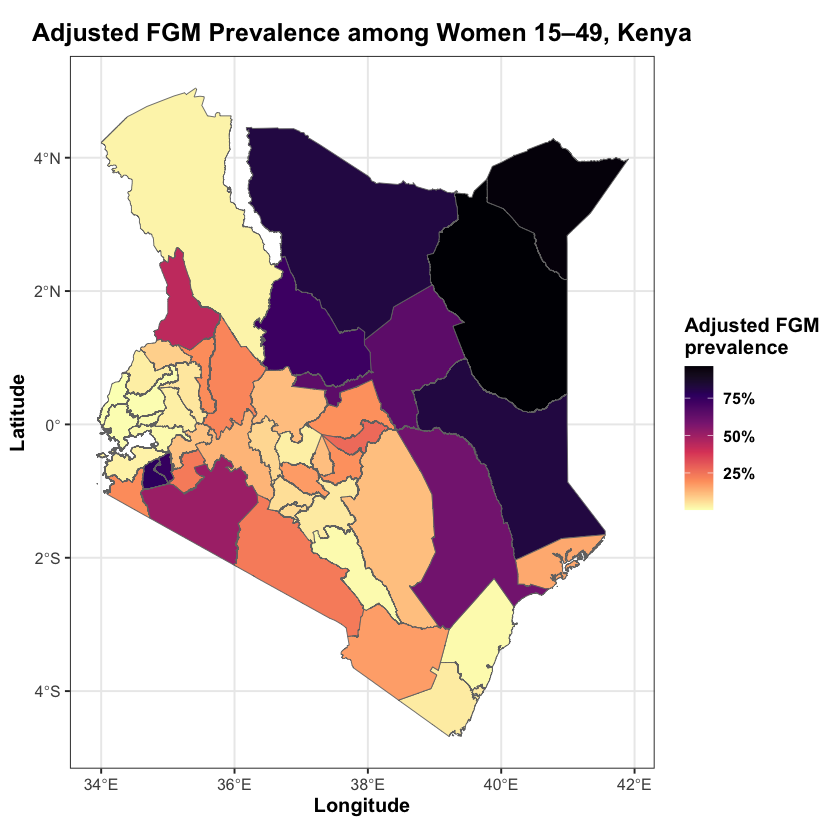

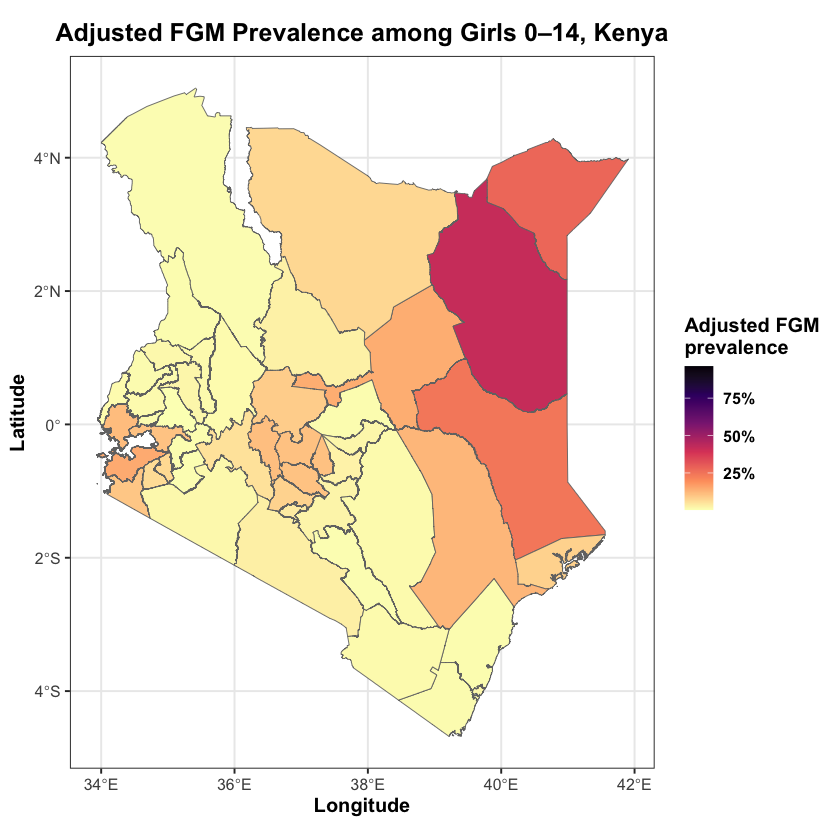

In [8]:
prevalence_long <- dplyr::bind_rows(self_prev,daughter_prev)
prevalence_limits <- range(prevalence_long$prevalence,na.rm=TRUE)
make_prevalence_map <- function(dat,title_text){
  m <- boundaries |> dplyr::left_join(dat,by="region")
  ggplot2::ggplot(m)+ggplot2::geom_sf(ggplot2::aes(fill=prevalence),color="grey45",linewidth=.25)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_prevalence_map <- make_prevalence_map(self_prev,paste("Adjusted FGM Prevalence among Women 15–49,",country_name))
daughter_prevalence_map <- make_prevalence_map(daughter_prev,paste("Adjusted FGM Prevalence among Girls 0–14,",country_name))
print(women_prevalence_map);print(daughter_prevalence_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_women_adjusted.png")),women_prevalence_map,width=9,height=8,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_girls_adjusted.png")),daughter_prevalence_map,width=9,height=8,dpi=300,bg="white")
# end

## 8. Separate overlays and combined comparison

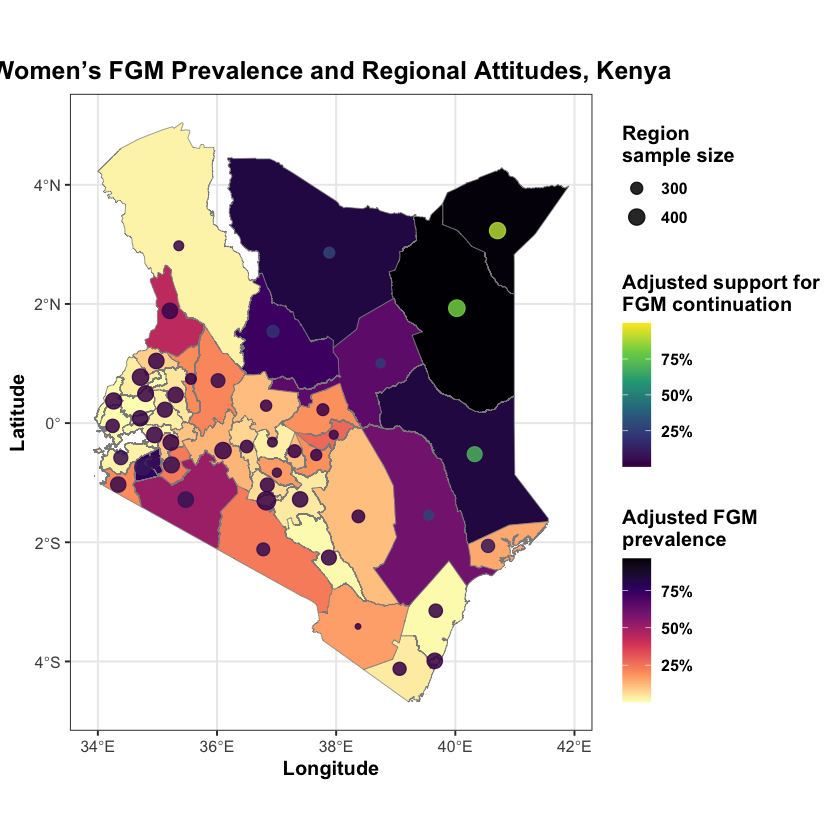

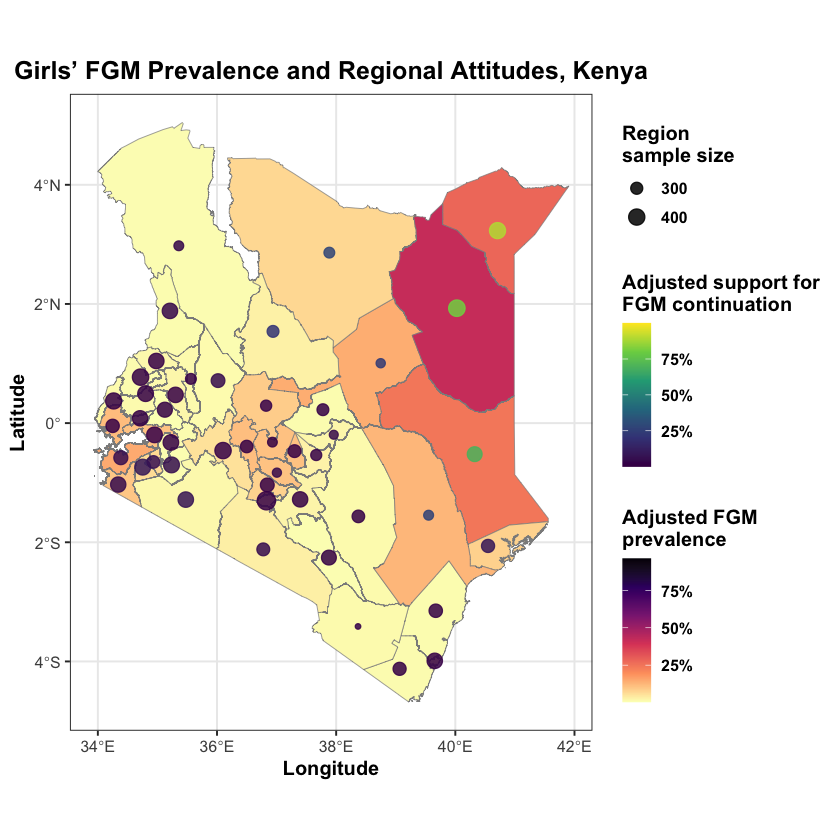

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Girls aged 0–14' in 'mbcsToSbcs': - substituted for – (U+2013)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Women aged 15–49' in 'mbcsToSbcs': - substituted for – (U+2013)”


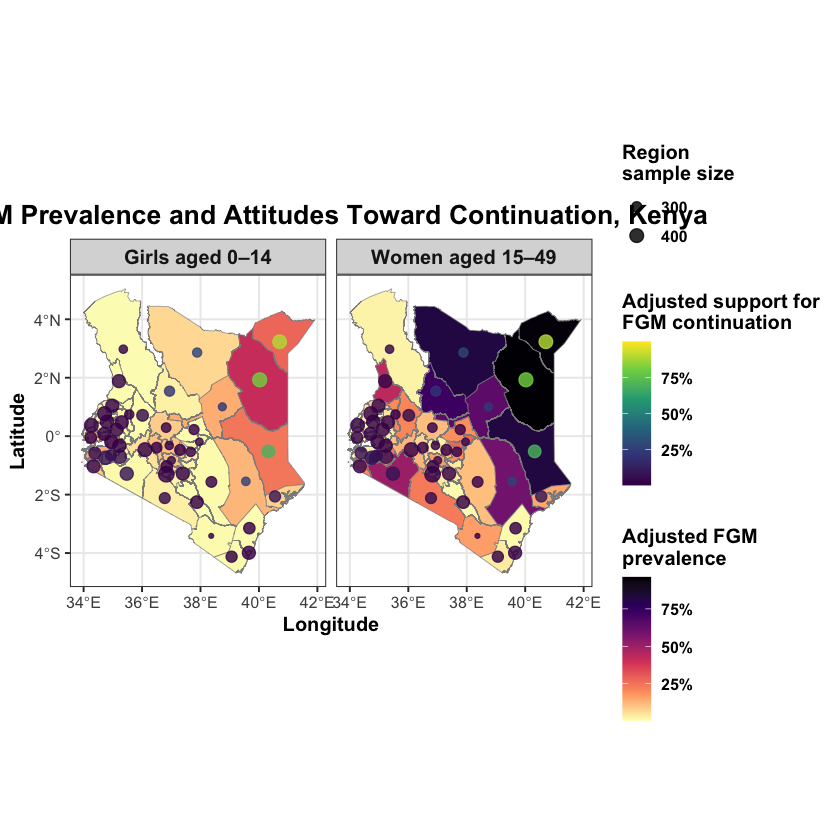

In [9]:
make_overlay <- function(prev,title_text){
  m <- boundaries |> dplyr::left_join(prev,by="region")
  ggplot2::ggplot()+
    ggplot2::geom_sf(data=m,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.2)+
    ggplot2::geom_point(data=region_plot_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.85)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",
      limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1))+
    ggplot2::scale_size_continuous(name="Region\nsample size",range=c(1.2,4.8),breaks=scales::pretty_breaks(3))+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_overlay <- make_overlay(self_prev,paste("Women’s FGM Prevalence and Regional Attitudes,",country_name))
girls_overlay <- make_overlay(daughter_prev,paste("Girls’ FGM Prevalence and Regional Attitudes,",country_name))
print(women_overlay);print(girls_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_women_prevalence_attitude.png")),women_overlay,width=11,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_girls_prevalence_attitude.png")),girls_overlay,width=11,height=8.5,dpi=300,bg="white")

map_data <- dplyr::bind_rows(
  boundaries |> dplyr::mutate(panel="Women aged 15–49") |> dplyr::left_join(self_prev,by=c("region","panel")),
  boundaries |> dplyr::mutate(panel="Girls aged 0–14") |> dplyr::left_join(daughter_prev,by=c("region","panel"))
)
point_data <- dplyr::bind_rows(
  region_plot_data |> dplyr::mutate(panel="Women aged 15–49"),
  region_plot_data |> dplyr::mutate(panel="Girls aged 0–14")
)
combined_overlay <- ggplot2::ggplot()+
  ggplot2::geom_sf(data=map_data,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.18)+
  ggplot2::geom_point(data=point_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.82)+
  ggplot2::facet_wrap(~panel,ncol=2)+
  ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
  ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",limits=c(0,1),breaks=c(.25,.5,.75),labels=scales::percent_format(accuracy=1))+
  ggplot2::scale_size_continuous(name="Region\nsample size",range=c(1,4),breaks=scales::pretty_breaks(3))+
  ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=paste("FGM Prevalence and Attitudes Toward Continuation,",country_name),x="Longitude",y="Latitude")+
  ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=16),strip.text=ggplot2::element_text(size=12))
print(combined_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.png")),combined_overlay,width=16,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.pdf")),combined_overlay,width=16,height=8.5,bg="white")
# end

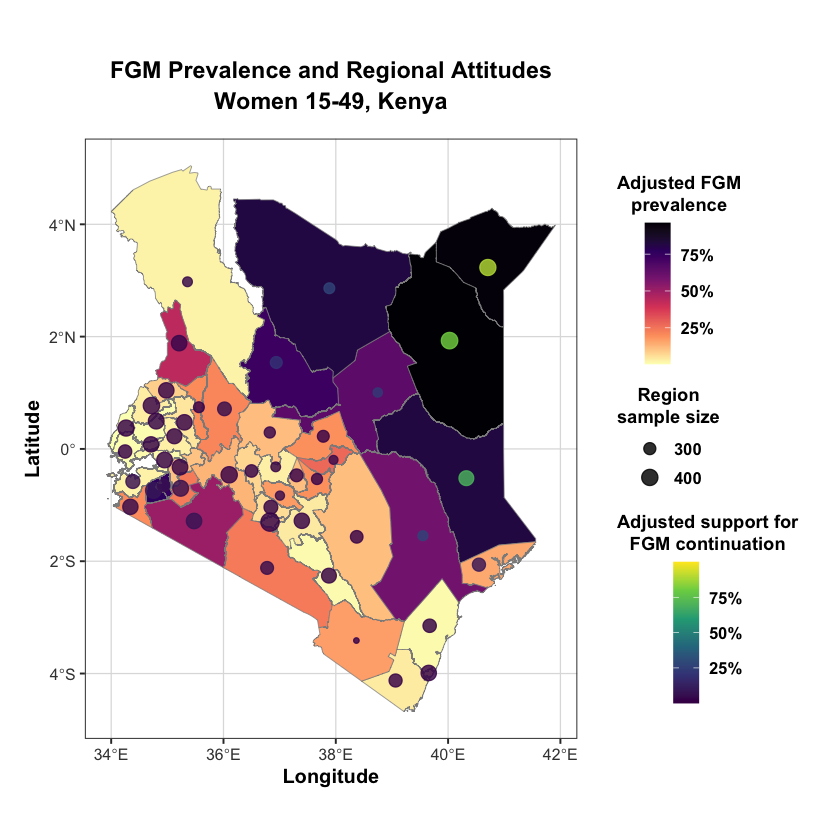

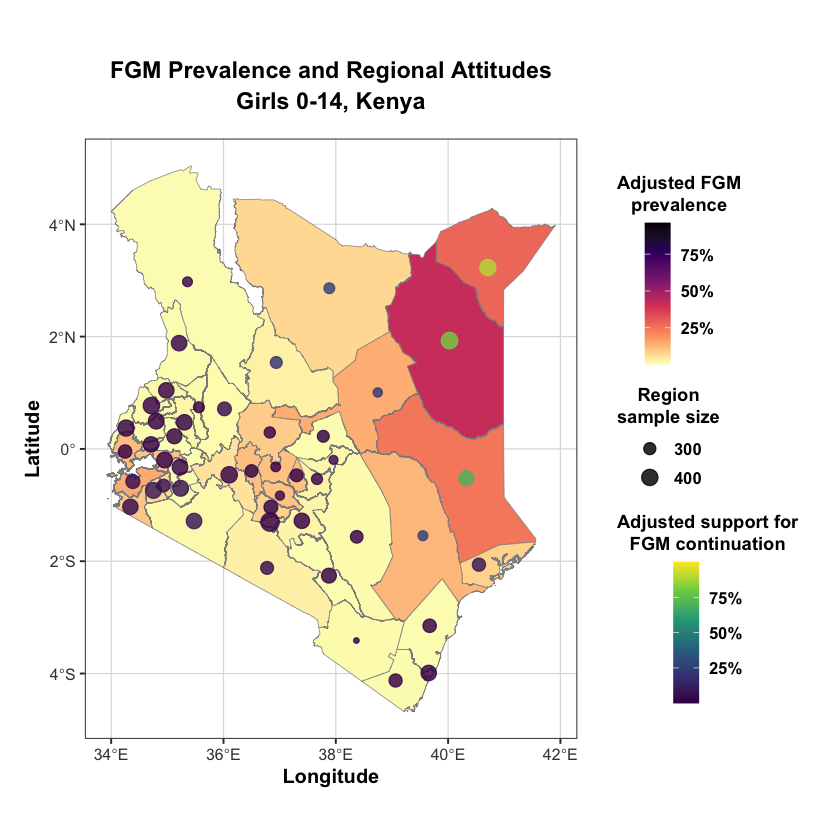

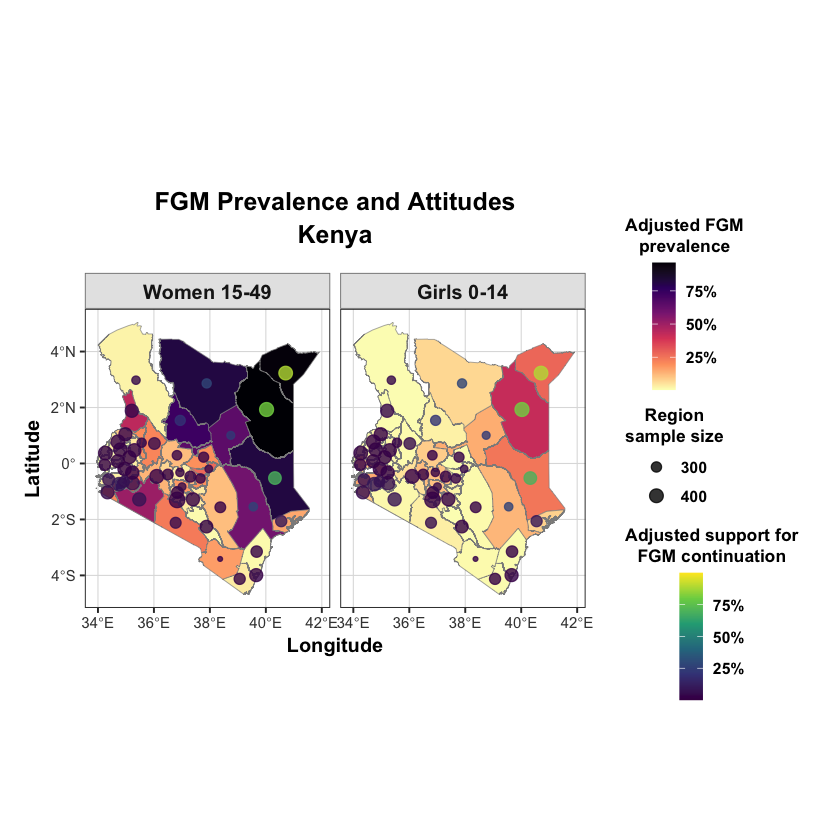

In [10]:
# ============================================================
# 8. Separate overlays and combined comparison
# ============================================================

# Consistent panel labels without special Unicode characters
panel_levels <- c(
  "Women 15-49",
  "Girls 0-14"
)

# ------------------------------------------------------------
# Function for separate prevalence-attitude overlay maps
# ------------------------------------------------------------

make_overlay <- function(
  prevalence_data,
  population_label
) {

  overlay_data <- boundaries |>
    dplyr::left_join(
      prevalence_data |>
        dplyr::select(
          region,
          prevalence
        ),
      by = "region"
    )

  ggplot2::ggplot() +

    # Region-level adjusted prevalence
    ggplot2::geom_sf(
      data = overlay_data,
      ggplot2::aes(
        fill = prevalence
      ),
      color = "grey55",
      linewidth = 0.20
    ) +

    # Region-level adjusted attitude, shown at the polygon centroid
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat,
        color = adjusted_support,
        size = n_unweighted
      ),
      alpha = 0.82
    ) +

    # Prevalence colour scale
    ggplot2::scale_fill_viridis_c(
      name = "Adjusted FGM\nprevalence",
      option = "magma",
      direction = -1,
      limits = prevalence_limits,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 1,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Attitude colour scale
    ggplot2::scale_color_viridis_c(
      name = "Adjusted support for\nFGM continuation",
      option = "viridis",
      limits = c(0, 1),
      breaks = c(
        0.25,
        0.50,
        0.75
      ),
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 3,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Region sample-size scale
    ggplot2::scale_size_continuous(
      name = "Region\nsample size",
      range = c(1.2, 4.8),
      breaks = scales::pretty_breaks(
        n = 3
      ),
      guide = ggplot2::guide_legend(
        order = 2,
        title.position = "top",
        title.hjust = 0.5
      )
    ) +

    ggplot2::coord_sf(
      datum = sf::st_crs(4326)
    ) +

    # Two-line title
    ggplot2::labs(
      title = paste0(
        "FGM Prevalence and Regional Attitudes\n",
        population_label,
        ", ",
        country_name
      ),
      x = "Longitude",
      y = "Latitude"
    ) +

    ggplot2::theme_bw(
      base_size = 12
    ) +

    ggplot2::theme(
      text = ggplot2::element_text(
        face = "bold",
        color = "black"
      ),

      plot.title = ggplot2::element_text(
        face = "bold",
        size = 14,
        hjust = 0.5,
        lineheight = 1.1,
        margin = ggplot2::margin(
          b = 15
        )
      ),

      axis.title = ggplot2::element_text(
        face = "bold",
        size = 12
      ),

      axis.text = ggplot2::element_text(
        face = "bold",
        color = "grey25"
      ),

      legend.position = "right",

      legend.title = ggplot2::element_text(
        face = "bold",
        size = 11,
        lineheight = 1.0
      ),

      legend.text = ggplot2::element_text(
        face = "bold",
        size = 10
      ),

      legend.box = "vertical",

      legend.spacing.y = grid::unit(
        0.45,
        "cm"
      ),

      legend.margin = ggplot2::margin(
        l = 12
      ),

      panel.grid.major = ggplot2::element_line(
        color = "grey87",
        linewidth = 0.35
      ),

      panel.grid.minor = ggplot2::element_blank(),

      plot.margin = ggplot2::margin(
        t = 20,
        r = 25,
        b = 15,
        l = 15
      )
    )
}

# ------------------------------------------------------------
# Separate overlay: women aged 15-49
# ------------------------------------------------------------

women_overlay <- make_overlay(
  prevalence_data = self_prev,
  population_label = "Women 15-49"
)

print(
  women_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.png"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.pdf"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ------------------------------------------------------------
# Separate overlay: girls aged 0-14
# ------------------------------------------------------------

girls_overlay <- make_overlay(
  prevalence_data = daughter_prev,
  population_label = "Girls 0-14"
)

print(
  girls_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.png"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.pdf"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ============================================================
# Prepare the combined two-panel comparison
# ============================================================

women_map_data <- boundaries |>
  dplyr::left_join(
    self_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Women 15-49"
  )

girls_map_data <- boundaries |>
  dplyr::left_join(
    daughter_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Girls 0-14"
  )

map_data <- dplyr::bind_rows(
  women_map_data,
  girls_map_data
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# Repeat the same regional attitude-symbol layer in both panels
point_data <- dplyr::bind_rows(
  region_plot_data |>
    dplyr::mutate(
      panel = "Women 15-49"
    ),
  region_plot_data |>
    dplyr::mutate(
      panel = "Girls 0-14"
    )
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# ============================================================
# Combined two-panel overlay
# ============================================================

combined_overlay <- ggplot2::ggplot() +

  # Region-level adjusted prevalence
  ggplot2::geom_sf(
    data = map_data,
    ggplot2::aes(
      fill = prevalence
    ),
    color = "grey55",
    linewidth = 0.18
  ) +

  # Region-level adjusted attitudes, shown at polygon centroids
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat,
      color = adjusted_support,
      size = n_unweighted
    ),
    alpha = 0.80
  ) +

  # Women first, girls second
  ggplot2::facet_wrap(
    ~panel,
    ncol = 2
  ) +

  # Shared prevalence scale
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted FGM\nprevalence",
    option = "magma",
    direction = -1,
    limits = prevalence_limits,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 1,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared attitude scale
  ggplot2::scale_color_viridis_c(
    name = "Adjusted support for\nFGM continuation",
    option = "viridis",
    limits = c(0, 1),
    breaks = c(
      0.25,
      0.50,
      0.75
    ),
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 3,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared sample-size scale
  ggplot2::scale_size_continuous(
    name = "Region\nsample size",
    range = c(1.0, 4.0),
    breaks = scales::pretty_breaks(
      n = 3
    ),
    guide = ggplot2::guide_legend(
      order = 2,
      title.position = "top",
      title.hjust = 0.5
    )
  ) +

  ggplot2::coord_sf(
    datum = sf::st_crs(4326)
  ) +

  # Brief two-line title
  ggplot2::labs(
    title = paste0(
      "FGM Prevalence and Attitudes\n",
      country_name
    ),
    x = "Longitude",
    y = "Latitude"
  ) +

  ggplot2::theme_bw(
    base_size = 12
  ) +

  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 15,
      hjust = 0.5,
      lineheight = 1.1,
      margin = ggplot2::margin(
        b = 15
      )
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey90",
      color = "grey50",
      linewidth = 0.5
    ),

    axis.title = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "grey25",
      size = 9
    ),

    legend.position = "right",

    legend.title = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      lineheight = 1.0
    ),

    legend.text = ggplot2::element_text(
      face = "bold",
      size = 9.5
    ),

    legend.box = "vertical",

    legend.spacing.y = grid::unit(
      0.35,
      "cm"
    ),

    legend.margin = ggplot2::margin(
      l = 12
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey87",
      linewidth = 0.30
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      t = 20,
      r = 25,
      b = 15,
      l = 15
    )
  )

print(
  combined_overlay
)

# ------------------------------------------------------------
# Save combined comparison
# ------------------------------------------------------------

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.png"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.pdf"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  bg = "white"
)

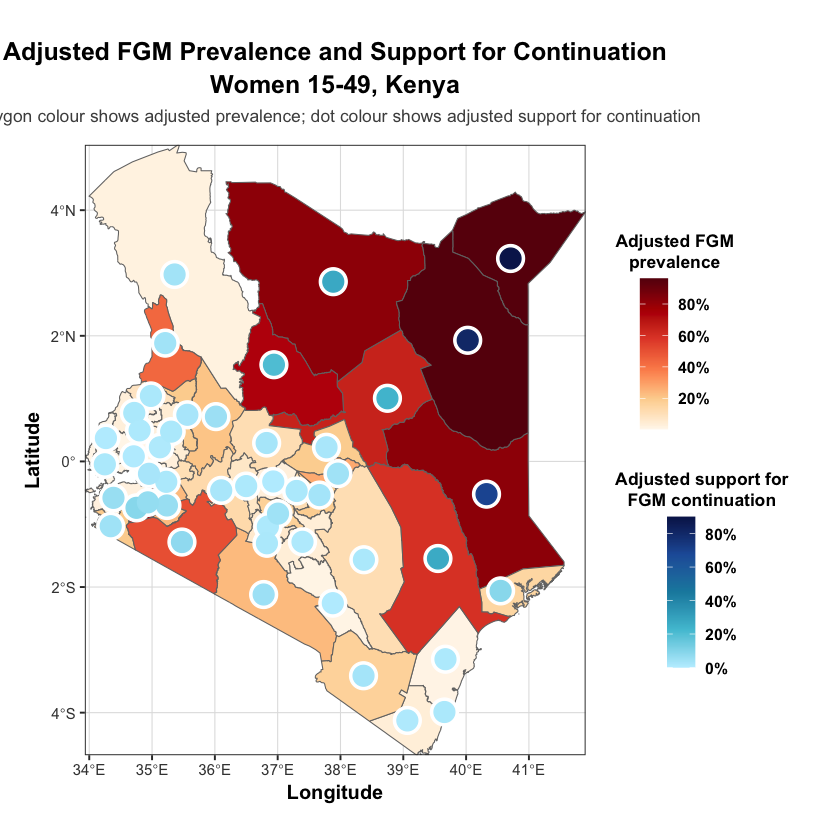

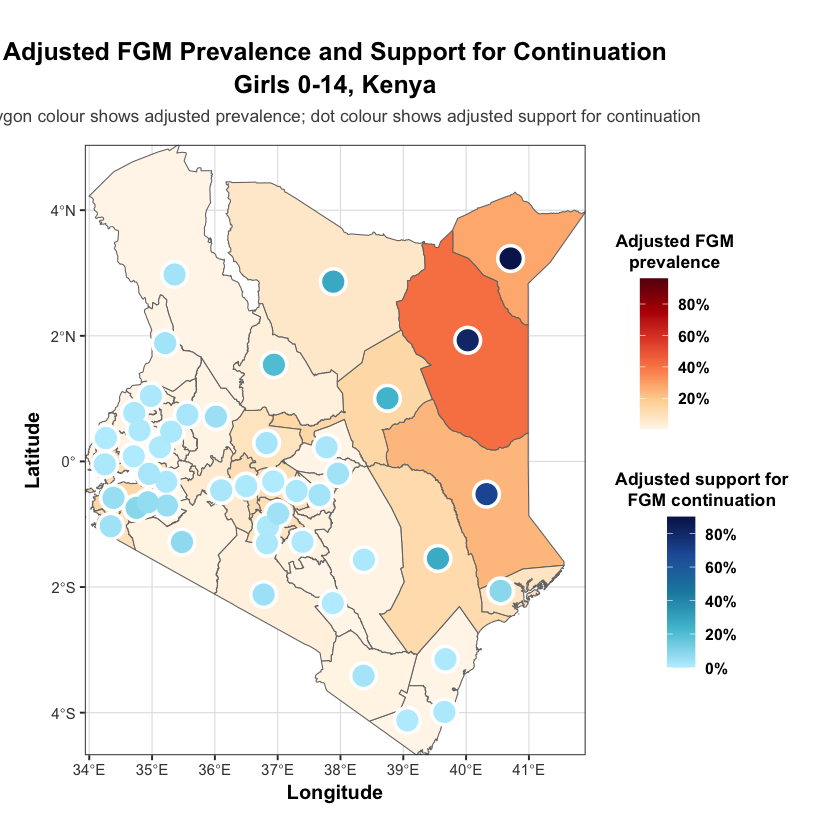

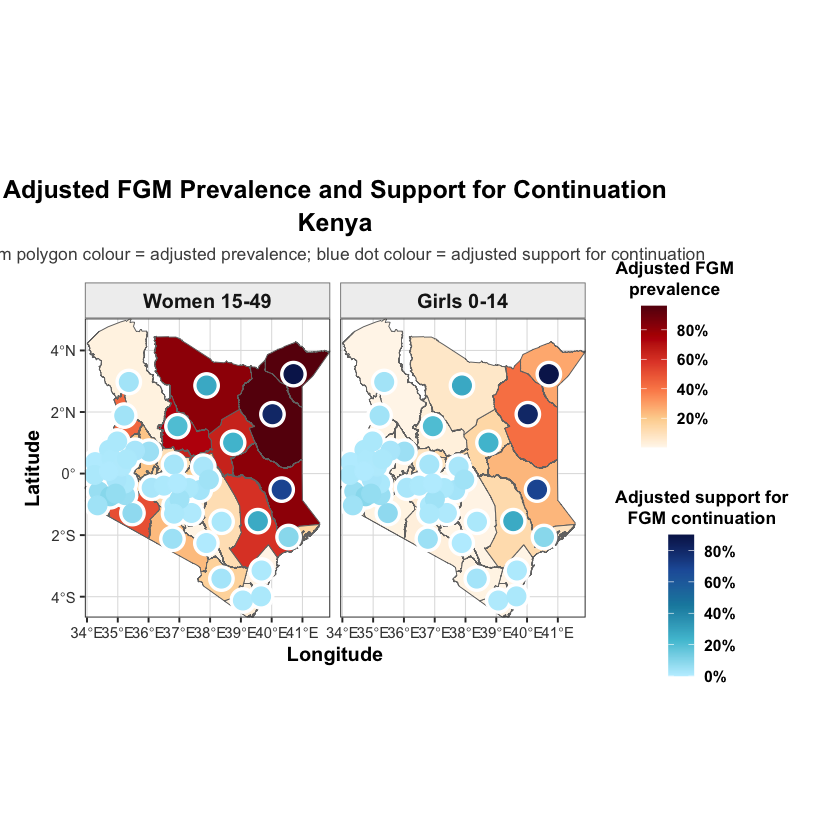

In [11]:
# ============================================================
# 8. Separate overlays and combined comparison
# ============================================================

panel_levels <- c(
  "Women 15-49",
  "Girls 0-14"
)

# ------------------------------------------------------------
# Colour palettes and limits
# ------------------------------------------------------------

# Warm sequential ramp for adjusted FGM prevalence polygons
prevalence_colours <- c(
  "#FFF7EC",
  "#FDD49E",
  "#FC8D59",
  "#E34A33",
  "#B30000",
  "#67000D"
)

# Distinct cool sequential ramp for adjusted support dots
support_colours <- c(
  "#BFEFFF",
  "#4FC3D7",
  "#168AAD",
  "#225EA8",
  "#081D58"
)

# Use the same prevalence scale across women and girls.
prevalence_limits <- range(
  c(
    self_prev$prevalence,
    daughter_prev$prevalence
  ),
  na.rm = TRUE
)

prevalence_breaks <- scales::breaks_pretty(n = 5)(
  prevalence_limits
)

# Kenya support estimates occupy only part of 0-100%.
# Start at zero but focus the scale on the observed range.
maximum_observed_support <- max(
  region_plot_data$adjusted_support,
  na.rm = TRUE
)

support_upper_limit <- min(
  1,
  max(
    0.25,
    ceiling(maximum_observed_support / 0.05) * 0.05
  )
)

support_limits <- c(
  0,
  support_upper_limit
)

support_breaks <- scales::breaks_pretty(n = 5)(
  support_limits
)

# ------------------------------------------------------------
# Shared map theme
# ------------------------------------------------------------

comparison_theme <- ggplot2::theme_bw(
  base_size = 12
) +
  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 15,
      hjust = 0.5,
      lineheight = 1.1,
      margin = ggplot2::margin(b = 7)
    ),

    plot.subtitle = ggplot2::element_text(
      face = "plain",
      size = 10.5,
      hjust = 0.5,
      color = "grey30",
      margin = ggplot2::margin(b = 12)
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey94",
      color = "grey50",
      linewidth = 0.5
    ),

    axis.title = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "grey25",
      size = 9
    ),

    legend.position = "right",

    legend.title = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      lineheight = 1
    ),

    legend.text = ggplot2::element_text(
      face = "bold",
      size = 9.5
    ),

    legend.box = "vertical",

    legend.spacing.y = grid::unit(
      0.45,
      "cm"
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey88",
      linewidth = 0.30
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      t = 18,
      r = 25,
      b = 15,
      l = 15
    )
  )

# ------------------------------------------------------------
# Function for separate overlay maps
# ------------------------------------------------------------

make_overlay <- function(
  prevalence_data,
  population_label
) {

  overlay_data <- boundaries |>
    dplyr::left_join(
      prevalence_data |>
        dplyr::select(
          region,
          prevalence
        ),
      by = "region"
    )

  ggplot2::ggplot() +

    # Adjusted FGM prevalence polygons
    ggplot2::geom_sf(
      data = overlay_data,
      ggplot2::aes(
        fill = prevalence
      ),
      color = "grey45",
      linewidth = 0.30
    ) +

    # White halo behind every attitude dot
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat
      ),
      color = "white",
      size = 7.5,
      alpha = 1
    ) +

    # Solid coloured attitude dots
    ggplot2::geom_point(
      data = region_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat,
        color = adjusted_support
      ),
      size = 5.5,
      alpha = 1
    ) +

    # Prevalence polygon scale
    ggplot2::scale_fill_gradientn(
      name = "Adjusted FGM\nprevalence",
      colours = prevalence_colours,
      limits = prevalence_limits,
      breaks = prevalence_breaks,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 1,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"),
        barwidth = grid::unit(0.60, "cm")
      )
    ) +

    # Support dot scale
    ggplot2::scale_color_gradientn(
      name = "Adjusted support for\nFGM continuation",
      colours = support_colours,
      limits = support_limits,
      breaks = support_breaks,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 2,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.2, "cm"),
        barwidth = grid::unit(0.60, "cm")
      )
    ) +

    ggplot2::coord_sf(
      datum = sf::st_crs(4326),
      expand = FALSE
    ) +

    ggplot2::labs(
      title = paste0(
        "Adjusted FGM Prevalence and Support for Continuation\n",
        population_label,
        ", ",
        country_name
      ),
      subtitle = paste0(
        "Polygon colour shows adjusted prevalence; ",
        "dot colour shows adjusted support for continuation"
      ),
      x = "Longitude",
      y = "Latitude"
    ) +

    comparison_theme
}

# ------------------------------------------------------------
# Separate overlay: women aged 15-49
# ------------------------------------------------------------

women_overlay <- make_overlay(
  prevalence_data = self_prev,
  population_label = "Women 15-49"
)

print(women_overlay)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.png"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.pdf"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ------------------------------------------------------------
# Separate overlay: girls aged 0-14
# ------------------------------------------------------------

girls_overlay <- make_overlay(
  prevalence_data = daughter_prev,
  population_label = "Girls 0-14"
)

print(girls_overlay)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.png"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.pdf"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ============================================================
# Prepare combined two-panel comparison
# ============================================================

women_map_data <- boundaries |>
  dplyr::left_join(
    self_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Women 15-49"
  )

girls_map_data <- boundaries |>
  dplyr::left_join(
    daughter_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Girls 0-14"
  )

map_data <- dplyr::bind_rows(
  women_map_data,
  girls_map_data
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# Repeat the regional support dots in both panels.
point_data <- dplyr::bind_rows(
  region_plot_data |>
    dplyr::mutate(
      panel = "Women 15-49"
    ),

  region_plot_data |>
    dplyr::mutate(
      panel = "Girls 0-14"
    )
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# ============================================================
# Combined two-panel overlay
# ============================================================

combined_overlay <- ggplot2::ggplot() +

  # Adjusted prevalence polygons
  ggplot2::geom_sf(
    data = map_data,
    ggplot2::aes(
      fill = prevalence
    ),
    color = "grey45",
    linewidth = 0.28
  ) +

  # White halo behind the support dots
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat
    ),
    color = "white",
    size = 6.8,
    alpha = 1
  ) +

  # Solid support dots
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat,
      color = adjusted_support
    ),
    size = 4.9,
    alpha = 1
  ) +

  ggplot2::facet_wrap(
    ~panel,
    ncol = 2
  ) +

  # Shared prevalence scale
  ggplot2::scale_fill_gradientn(
    name = "Adjusted FGM\nprevalence",
    colours = prevalence_colours,
    limits = prevalence_limits,
    breaks = prevalence_breaks,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 1,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(3, "cm"),
      barwidth = grid::unit(0.55, "cm")
    )
  ) +

  # Shared support scale
  ggplot2::scale_color_gradientn(
    name = "Adjusted support for\nFGM continuation",
    colours = support_colours,
    limits = support_limits,
    breaks = support_breaks,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 2,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(3, "cm"),
      barwidth = grid::unit(0.55, "cm")
    )
  ) +

  ggplot2::coord_sf(
    datum = sf::st_crs(4326),
    expand = FALSE
  ) +

  ggplot2::labs(
    title = paste0(
      "Adjusted FGM Prevalence and Support for Continuation\n",
      country_name
    ),
    subtitle = paste0(
      "Warm polygon colour = adjusted prevalence; ",
      "blue dot colour = adjusted support for continuation"
    ),
    x = "Longitude",
    y = "Latitude"
  ) +

  comparison_theme

print(combined_overlay)

# ------------------------------------------------------------
# Save combined comparison
# ------------------------------------------------------------

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.png"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.pdf"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  bg = "white"
)

## Interpretation

The prevalence polygons and attitude symbols are related but different outcomes. Polygon colour represents covariate-adjusted FGM prevalence among women or girls. Point colour represents covariate-adjusted support for continuing FGM among interviewed women aggregated within each region, while point size represents the regional attitude sample. Points are placed at polygon centroids only as map symbols; they are not DHS survey locations. The same symbol layer and scales are used in both overlays. Spatial coincidence is descriptive, not causal.

In [12]:
cat("Completed. Outputs saved to:",normalizePath(output_dir,mustWork=FALSE),"\n")
cat("Standalone maps: regional attitude, women prevalence, girls prevalence.\n")
cat("Overlay maps: women, girls, and combined two-panel comparison.\n")
# end

Completed. Outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/FGM_Risk_Attitude_Prevelance/03_Outputs/KEN/Prevalence_Attitude_Comparison_v2 


Standalone maps: regional attitude, women prevalence, girls prevalence.


Overlay maps: women, girls, and combined two-panel comparison.
